In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import seaborn as sns
from utils.plots import *
from utils.figures import cmap

from scipy.stats import ks_2samp
from scipy.stats import linregress

FIG = 'fig_covariates'
meta_fpath = '../../dfs/aurora_test_ppg_df.csv'
# data_dir = Path('../../experiments/aurora_ppg')
data_fpath = '../fig4/fig4_df.csv'


In [3]:
df_meta = pd.read_csv(meta_fpath)
df_data = pd.read_csv(data_fpath)

cols = [
    'fitzpatrick_scale',

    'hr_ekg',
    'hrv_ekg',

    'age',
    'height',
    'weight',
    'bmi',
    'gender',

    'self_report_htn',
    'high_blood_pressure',
    'coronary_artery_disease',
    'diabetes',
    'arrythmia',
    'previous_heart_attack',
    'previous_stroke',
    'heart_failure',
    'aortic_stenosis',
    'valvular_heart_disease',
    'other_cv_diseases',
    'cvd_meds',

    'motion_level',
]
df = pd.merge(df_data, df_meta[cols], left_on='i', right_index=True, how='left')
df['female'] = (df['gender'] == 'F')
cols[cols.index('gender')] = 'female'

for col in cols.copy():
    if df[col].nunique() == 1:
        cols.remove(col)
        print('no coverage:', col)
        df.drop(columns=col, inplace=True)

df[cols].info()
df['motion_level'] -= df['motion_level'].min()
df['motion_level'] /= df['motion_level'].max() / 10 



no coverage: coronary_artery_disease
no coverage: previous_heart_attack
no coverage: previous_stroke
no coverage: heart_failure
no coverage: aortic_stenosis
no coverage: valvular_heart_disease
<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   fitzpatrick_scale    30 non-null     float64
 1   hr_ekg               180 non-null    float64
 2   hrv_ekg              180 non-null    float64
 3   age                  210 non-null    float64
 4   height               210 non-null    float64
 5   weight               210 non-null    float64
 6   bmi                  210 non-null    float64
 7   female               210 non-null    bool   
 8   self_report_htn      210 non-null    str    
 9   high_blood_pressure  210 non-null    int64  
 10  diabetes             210 non-null    int64  
 11  arrythmia            210 non-null    int64  
 12  other_cv

0.48495300177635314
0.8958013026509919
0.5479449461862231
0.8233360878546305
0.6098315987267449
0.7144068042970633
p = 0.9284088223913491
p = 0.8974761754496609
p = 0.4606883982136866
p = 0.30361348611943323
p = 0.5576656625599328


/var/folders/z2/2j1043_j3yj2ttd_nxtg4z2h0000gn/T/ipykernel_22016/1083494051.py:99: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.savefig(f'{FIG}.pdf', transparent=True)
/var/folders/z2/2j1043_j3yj2ttd_nxtg4z2h0000gn/T/ipykernel_22016/1083494051.py:99: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.savefig(f'{FIG}.pdf', transparent=True)
/var/folders/z2/2j1043_j3yj2ttd_nxtg4z2h0000gn/T/ipykernel_22016/1083494051.py:100: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
/Users/psr/opt/anaconda3/envs/pulse_deconv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: tight_layout not applied: number of columns in subplot specifications must be multiples of one another.
  fig.canvas.print_figure(bytes

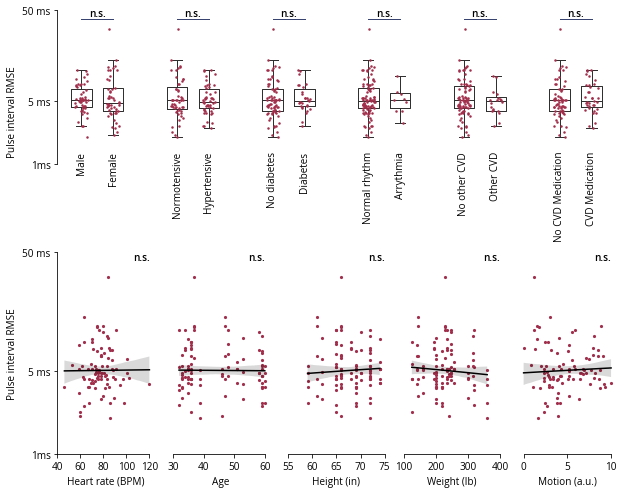

In [4]:
metric = 'zp_rmse'
title = 'Pulse interval RMSE'
method = 'T_bpd'

df_temp = df.copy()
df_temp = df_temp[df_temp['method']==method]


covariates_binary = [
    ('female', 'Male', 'Female'),
    ('high_blood_pressure', 'Normotensive', 'Hypertensive'),
    ('diabetes', 'No diabetes', 'Diabetes'),
    ('arrythmia', 'Normal rhythm', 'Arrythmia'),
    ('other_cv_diseases', 'No other CVD', 'Other CVD'),
    ('cvd_meds', 'No CVD Medication', 'CVD Medication'),
]


plt.figure(figsize=(10,8))
for i, (covariate, xl1, xl2) in enumerate(covariates_binary):

    plt.subplot(2,len(covariates_binary),i+1)
    plt.semilogy()

    np.random.seed(0)
    boxwidth=0.8
    sns.stripplot(df_temp, x=covariate, y=metric, size=2.5, jitter=0.25*boxwidth, c=cp[1])
    sns.boxplot(df_temp, x=covariate, y=metric,
                fill=None, color='#303030', width=0.8*boxwidth, fliersize=0)

    plt.gca().tick_params(axis="x", length=0)
    plt.minorticks_off()

    plt.xticks([0, 1], [xl1, xl2], rotation=90)
    plt.gca().tick_params(axis="x", direction="in", pad=-61)
    plt.xlabel(None)

    result = ks_2samp(df_temp[metric][df_temp[covariate]==0], df_temp[metric][df_temp[covariate]==1])
    print(result.pvalue)

    plt.yticks([0.001, 0.005, 0.05, 0.5, 5], ['1ms', '5 ms', '50 ms', '500 ms', '5s'])
    plt.ylim(0.0003, 0.05)
    if i == 0:
        plt.ylabel(title)
        sns.despine(ax=plt.gca(), bottom=True, trim=True)
    else:
        plt.yticks([])
        plt.ylabel(None)
        sns.despine(ax=plt.gca(), bottom=True, left=True, trim=True)
    plt.xlim(-0.75, 1.75)

    plt.plot([0, 1], [0.04, 0.04])
    plt.text(0.5, 0.043, 'n.s.', ha='center', fontdict={'weight':'semibold'})


covariates_continuous = [
    ('hr_ekg', 'Heart rate (BPM)', [40, 60, 80, 100, 120]),
    ('age', 'Age', [30, 40, 50, 60]),
    ('height', 'Height (in)', [55, 60, 65, 70, 75]),
    ('weight', 'Weight (lb)', [100, 200, 300, 400]),
    ('motion_level', 'Motion (a.u.)', [0, 5, 10]),
]


for i, (covariate, name, xticks) in enumerate(covariates_continuous):

    plt.subplot(2,len(covariates_continuous),len(covariates_continuous)+i+1)
    plt.semilogy()

    np.random.seed(0)
    boxwidth=0.8
    plt.scatter(df_temp[covariate], df_temp[metric], s=10, c=cp[1], lw=0)
    plt.gca().set_xmargin(0.05)

    # plt.gca().tick_params(axis="x", length=0)
    plt.minorticks_off()

    df_clean = df_temp[df_temp[metric] < 0.01].dropna(subset=[covariate, metric])
    result = linregress(df_clean[covariate].values, df_clean[metric].values, )
    print('p =', result.pvalue)
    sns.regplot(df_clean, x=covariate, y=metric, scatter=False, color='k')

    plt.yticks([0.001, 0.005, 0.05, 0.5, 5], ['1ms', '5 ms', '50 ms', '500 ms', '5s'])
    plt.ylim(0.001, 0.05)
    plt.xticks(xticks)
    plt.xlabel(name)

    if i == 0:
        plt.ylabel(title)
        sns.despine(ax=plt.gca(), trim=True)
    else:
        plt.yticks([])
        plt.ylabel(None)
        sns.despine(ax=plt.gca(), left=True, trim=True)
    # plt.xlim(-1, 2)

    plt.text(xticks[-1], 0.05, 'n.s.', va='top', ha='right', fontdict={'weight':'semibold'})

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
